In [21]:
import numpy as np
from sim_library.constants import k_eff, dR, m, kb
from scipy.constants import hbar, pi
import matplotlib.pyplot as plt
from pathlib import Path
from sim_library.sequences import RR3_gate
from sim_library.simulation import simulate_alg_cooling
from sim_library.plotting import plot_coolingcycles_22, fit_gaussian
from sim_library.data_io import load_p_dists
from matplotlib.ticker import MultipleLocator

### Generate data

In [ ]:
# Set ensemble parameters
N = 10000
initial_temp = 5.9e-6

rabi_freq = 2*pi*4e5
rabi_time = 2*pi/rabi_freq

time_steps = 1

RR3 = RR3_gate(rabi_freq=rabi_freq, time_steps=time_steps, bs_corr=True, pi_corr=True, freq_dep=True)
RR3.build_seq()

# Cooling parameters
cycles = 16
pumping_route = 'f3' # optical pumping via either F'=2 ('f2') or F'=3 ('f3')

p_min = -16
p_max = 16
basis = np.arange(p_min, p_max + 1)

initial_state = np.zeros(shape=len(basis), dtype=np.complex128)
initial_state[19] = 1
initial_state = initial_state/ np.linalg.norm(initial_state)

# Intensity noise
beam_profile = np.random.normal(loc=1.0, scale=0.0167, size=N) 

# Simulate cooling sequence
moms_list, fracs_list, _ = simulate_alg_cooling(basis=basis, sequence=RR3, n_atoms=N, temp=initial_temp, initial_state=initial_state, beam_profile=beam_profile, cycles=cycles, rabi_freq=rabi_freq, pumping_route=pumping_route,
                                                        # save_dir='data/algorithmic cooling/paper26/'
                                                        )

In [19]:
# KEY:
# 1 - freq indep uncorrected
# 2 - freq indep corrected
# 3 - freq dep uncorrected
# 4 - freq dep corrected

path = Path("data\\algorithmic cooling\\paper26\\2026-11-25_algcooling_f3_16cycles_6muK_10000atoms_4e+05Hz.h5")
loaded_dict = load_p_dists(file_path=path)
moms_list1 = loaded_dict["p_list"]
fracs_list1 = loaded_dict["weights_list"]

# Convert to units of hbark
moms_list1 = [mom / (hbar * k_eff) for mom in moms_list1]

# Finds highest/lowest momentum values across entire data
global_min = min([min(m) for m in moms_list1])
global_max = max([max(m) for m in moms_list1])
global_range1 = (global_min, global_max)

path = Path("data\\algorithmic cooling\\paper26\\2026-11-25_algcooling_f3_16cycles_6muK_10000atoms_4e+05Hz_1.h5")
loaded_dict = load_p_dists(file_path=path)
moms_list2 = loaded_dict["p_list"]
fracs_list2 = loaded_dict["weights_list"]

# Convert to units of hbark
moms_list2 = [mom / (hbar * k_eff) for mom in moms_list2]

# Finds highest/lowest momentum values across entire data
global_min = min([min(m) for m in moms_list2])
global_max = max([max(m) for m in moms_list2])
global_range2 = (global_min, global_max)

path = Path("data\\algorithmic cooling\\paper26\\2026-11-25_algcooling_f3_16cycles_6muK_10000atoms_4e+05Hz_2.h5")
loaded_dict = load_p_dists(file_path=path)
moms_list3 = loaded_dict["p_list"]
fracs_list3 = loaded_dict["weights_list"]

# Convert to units of hbark
moms_list3 = [mom / (hbar * k_eff) for mom in moms_list3]

# Finds highest/lowest momentum values across entire data
global_min = min([min(m) for m in moms_list3])
global_max = max([max(m) for m in moms_list3])
global_range3 = (global_min, global_max)

path = Path("data\\algorithmic cooling\\paper26\\2026-11-25_algcooling_f3_16cycles_6muK_10000atoms_4e+05Hz_3.h5")
loaded_dict = load_p_dists(file_path=path)
moms_list4 = loaded_dict["p_list"]
fracs_list4 = loaded_dict["weights_list"]

# Convert to units of hbark
moms_list4 = [mom / (hbar * k_eff) for mom in moms_list4]

# Finds highest/lowest momentum values across entire data
global_min = min([min(m) for m in moms_list4])
global_max = max([max(m) for m in moms_list4])
global_range4 = (global_min, global_max)

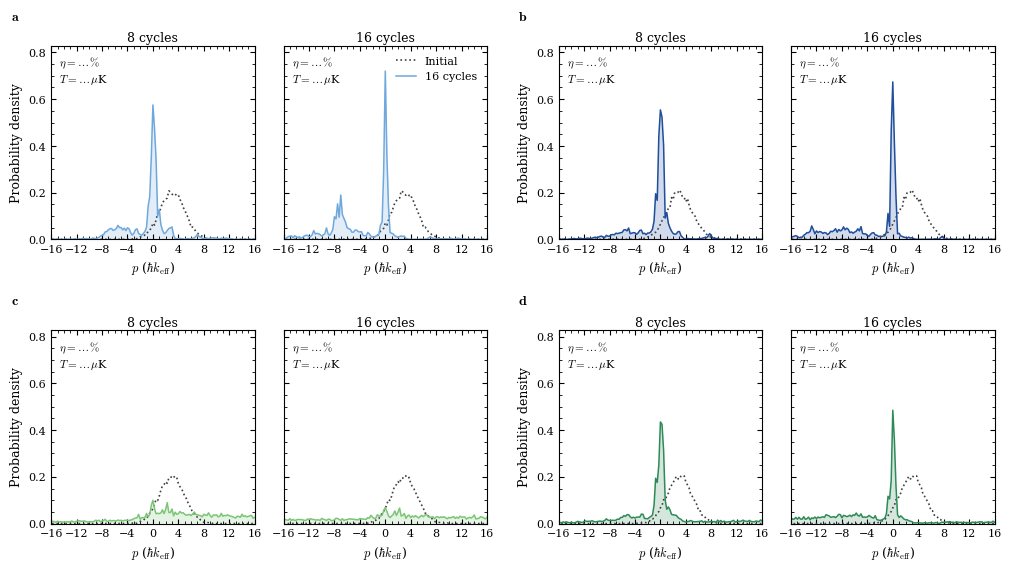

In [37]:


# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
# KEY: 1 - freq indep uncorrected, 2 - freq indep corrected,
#      3 - freq dep uncorrected,   4 - freq dep corrected
base = Path("data") / "algorithmic cooling" / "paper26"
stem = "2026-11-25_algcooling_f3_16cycles_6muK_10000atoms_4e+05Hz"
# Order = panels a, b, c, d  (datasets 3, 4 -> a, b ; datasets 1, 2 -> c, d)
paths = [
    base / f"{stem}_2.h5",   # a: dataset 3
    base / f"{stem}_3.h5",   # b: dataset 4
    base / f"{stem}.h5",     # c: dataset 1
    base / f"{stem}_1.h5",   # d: dataset 2
]
# Panel colours: a, b greens; c, d blues
PANEL_COLOURS = [ "#6fa8dc","#1f4e9c",  "#7cc576", "#2e8b57" ]
panel_titles = [None, None, None, None]  # optional short panel descriptions, e.g. 'Freq. indep., uncorrected'

FIG_WIDTH = 10        # overall figure width (inches)
FIG_HEIGHT = 5.6        # overall figure height (inches)
CYCLES = (8, 16)        # cycles shown in the left/right plot of each panel
BIN_WIDTH = 0.25        # histogram bin width (hbar k_eff), p = 0 sits at a bin centre
XTICK_STEP = 4          # major tick spacing (hbar k_eff)
YLIM = None             # None -> common y limit auto-scaled across all subfigures
SAVE_PATH = "cooling_figure.pdf"  # set to '' to skip saving

# Index into p_list / weights_list after n cooling cycles: index = 2n (index 0 = initial distribution).
def cycle_index(n: int) -> int:
    return 2 * n

# ----------------------------------------------------------------------------
# Style
# ----------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.1,
})
INIT_COL = "0.25"

# ----------------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------------
def load_dataset(path: Path) -> dict:
    d = load_p_dists(file_path=path)
    moms = [m / (hbar * k_eff) for m in d["p_list"]]  # convert to units of hbar k_eff
    return {
        "moms": moms,
        "fracs": d["weights_list"],
        "basis": np.asarray(d["basis"]),
        "range": (min(m.min() for m in moms), max(m.max() for m in moms)),
    }


def bin_setup(data_range, bin_width):
    """Fixed bin edges with p = 0 at a bin centre (same convention as plot_coolingcycles_*)."""
    edge_min = np.floor(data_range[0] / bin_width)
    edge_max = np.ceil(data_range[1] / bin_width)
    edges = (np.arange(edge_min, edge_max + 2) - 0.5) * bin_width
    mids = edges[:-1] + bin_width / 2
    return edges, mids


def density(moms, fracs, edges):
    counts, _ = np.histogram(moms, weights=fracs, bins=edges, density=True)
    return counts


# ----------------------------------------------------------------------------
# Load + histogram everything first so y limits can be shared
# ----------------------------------------------------------------------------
datasets = [load_dataset(p) for p in paths]

hists = []  # hists[panel] = dict(mids, init, finals=[...])
for ds in datasets:
    edges, mids = bin_setup(ds["range"], BIN_WIDTH)
    init = density(ds["moms"][0], ds["fracs"][0], edges)
    finals = [density(ds["moms"][cycle_index(n)], ds["fracs"][cycle_index(n)], edges) for n in CYCLES]
    hists.append({"mids": mids, "init": init, "finals": finals})

if YLIM is None:
    peak = max(max(h["init"].max(), *(f.max() for f in h["finals"])) for h in hists)
    YLIM = peak * 1.15

# ----------------------------------------------------------------------------
# Figure: 2x2 grid of panels (subfigures), each holding two side-by-side axes
# ----------------------------------------------------------------------------
fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT), layout="constrained")
subfigs = fig.subfigures(2, 2, wspace=0.03, hspace=0.03)

for k, (sf, ds, h) in enumerate(zip(subfigs.flat, datasets, hists)):
    label = "abcd"[k]
    title = rf"$\bf{{{label}}}$" + (f"   {panel_titles[k]}" if panel_titles[k] else "")
    sf.suptitle(title, x=0.01, ha="left", fontsize=10)

    axes = sf.subplots(1, 2, sharey=True)
    basis = ds["basis"]

    for j, (ax, n, final) in enumerate(zip(axes, CYCLES, h["finals"])):
        ax.plot(h["mids"], h["init"], ls=":", c=INIT_COL, lw=1.2, label="Initial")
        col = PANEL_COLOURS[k]
        ax.plot(h["mids"], final, c=col, label=f"{n} cycles")
        ax.fill_between(h["mids"], final, color=col, alpha=0.2, lw=0)

        ax.set_xlim(basis[0], basis[-1])
        ax.set_ylim(0, YLIM)
        ax.xaxis.set_major_locator(MultipleLocator(XTICK_STEP))
        ax.set_xlabel(r"$p$ ($\hbar k_{\mathrm{eff}}$)")
        ax.set_title(f"{n} cycles", fontsize=9, pad=3)

        # Efficiency / temperature placeholders -- fill in manually
        ax.text(0.04, 0.95,
                r"$\eta = \ldots\,\%$" + "\n" + r"$T = \ldots\,\mu$K",
                transform=ax.transAxes, ha="left", va="top", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.8))

    axes[0].set_ylabel("Probability density")
    axes[1].tick_params(labelleft=False)

# One legend (on first panel's right plot)
subfigs.flat[0].axes[1].legend(loc="upper right", frameon=False, handlelength=1.8)

if SAVE_PATH:
    fig.savefig(SAVE_PATH, dpi=600, bbox_inches="tight")

plt.show()


Efficiency: 37.853 +/- 0.014307 %
Temperature: 0.06053 +/- 0.007391 muK
Center: 0.0061356 +/- 0.0058218 hbark
Reduced chi-squared: 3.6665


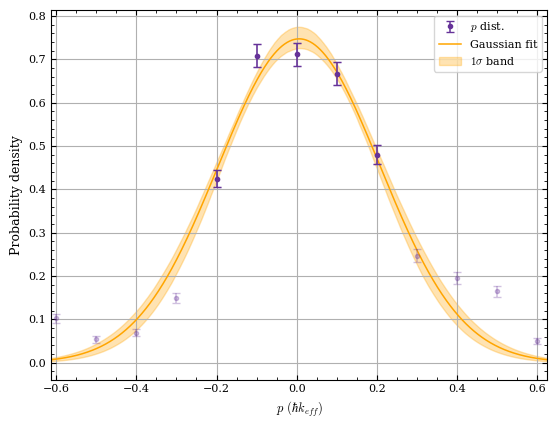

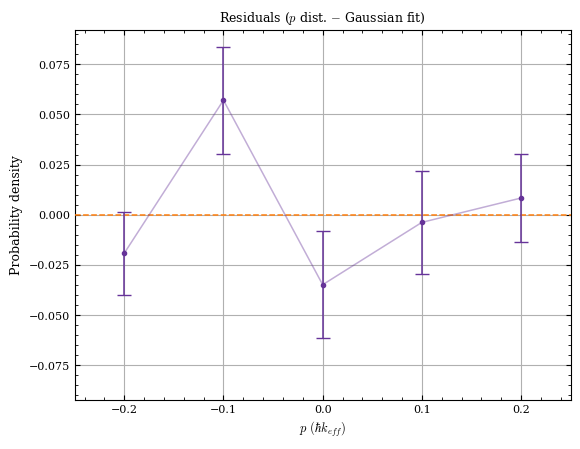

In [26]:
### Fitting gaussian with auto peak detection ###

# Width of domain relative to width of truncated data
# Default is 1
xscale = 3

# Fraction of peak height used to truncate data
# Default is 0.5 (i.e. FWHM)
threshold = 0.5

# Resolution (in units of hbar*k_eff)
bin_width = 0.1

amp, T, shift, errs, _, _ = fit_gaussian(moms_list3[-1], fracs=fracs_list3[-1], range = global_range3, bin_width=bin_width, xscale=xscale, threshold=threshold,
                                   plot=True, 
                                   print_vals=True,
                                   joindata=False,
                                   plot_residuals=True
                                    )

Efficiency: 44.289 +/- 0.015384 %
Temperature: 0.089016 +/- 0.00949 muK
Center: -0.022839 +/- 0.0068224 hbark
Reduced chi-squared: 2.3641


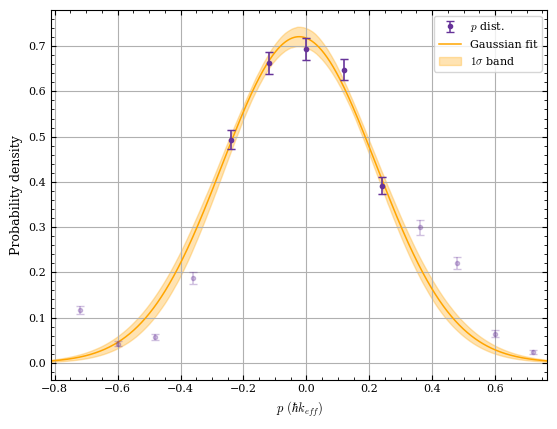

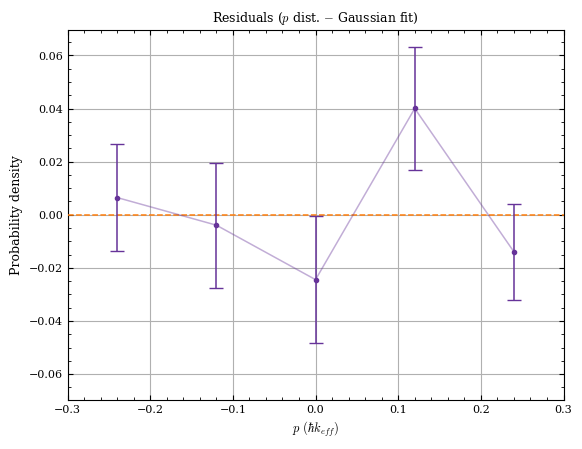

In [34]:
### Fitting gaussian with auto peak detection ###

# Width of domain relative to width of truncated data
# Default is 1
xscale = 3

# Fraction of peak height used to truncate data
# Default is 0.5 (i.e. FWHM)
threshold = 0.5

# Resolution (in units of hbar*k_eff)
bin_width = 0.12

amp, T, shift, errs, _, _ = fit_gaussian(moms_list4[-1], fracs=fracs_list4[-1], range = global_range4, bin_width=bin_width, xscale=xscale, threshold=threshold,
                                   plot=True, 
                                   print_vals=True,
                                   joindata=False,
                                   plot_residuals=True
                                    )